In [1]:
# ==== 4-panel KD heatmaps across tension levels =========================
# Assumes you already have: speciesNames, tau, ymax, y0, w_vec, n, EC50, bv, pv,
# NetfluxODE_5.ODEfunc, NetfluxODE_5_sensitivity.ODEfunc, and (optionally)
# 'phenotypic_outputs' and/or 'top_10_influential' / 'top_10_influential_nodes'.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.integrate import ode

In [2]:

from model_DOF_clustering_5 import objective_function, load_ko_and_expectation_data, wlen, family_id_vector, build_weight_vector

import NetfluxODE_5
import NetfluxODE_5_sensitivity
import NetfluxODE_5_params
 # 
[speciesNames, tau, ymax, y0, w, n, EC50] = NetfluxODE_5_params.loadParams()

# Read the CSV file
loss_log_df = pd.read_csv("loss_log_DOF_cluster.csv")
# Find the row with the smallest value in the last column
min_loss_row = loss_log_df.loc[loss_log_df.iloc[:, -1].idxmin()]
# Extract the vector using all columns from the first to the penultimate column
vector = np.array([1.01915194, 1.09999999, 0.94966909, 1.1, 0.62873844])
print(vector)
# Convert the vector to a numpy array
w_vec = build_weight_vector(vector, family_id_vector)

bas=0.1
y0=bas*np.ones(len(y0))

EC50v = 0.587798419904243
nv    = 1.39569768592174
bv    = 0.283201091629315
pv    = 0.653814229335876

EC50=EC50v*np.ones(len(EC50))  #all

n=nv*np.ones(len(n)) #all


[1.01915194 1.09999999 0.94966909 1.1        0.62873844]


In [3]:
AngII = 0 
AT1R = 1 
AGT = 2 
ACE = 3 
NOX = 4 
ROS = 5 
ET1 = 6 
ETAR = 7 
DAG = 8 
PKC = 9 
AC = 10 
cAMP = 11 
PKA = 12 
CREB = 13 
CBP = 14 
TGFB = 15 
TGFB1R = 16 
smad3 = 17 
smad7 = 18 
latentTGFB = 19 
PDGF = 20 
PDGFR = 21 
cGMP = 22 
PKG = 23 
mechanical = 24 
B1int = 25 
Rho = 26 
ROCK = 27 
Ca = 28 
IL6 = 29 
gp130 = 30 
STAT = 31 
IL1 = 32 
IL1RI = 33 
TNFa = 34 
TNFaR = 35 
NFKB = 36 
PI3K = 37 
Akt = 38 
p38 = 39 
TRAF = 40 
ASK1 = 41 
MKK3 = 42 
PP1 = 43 
JNK = 44 
abl = 45 
Rac1 = 46 
MEKK1 = 47 
MKK4 = 48 
ERK = 49 
Ras = 50 
Raf = 51 
MEK1 = 52 
FAK = 53 
epac = 54 
Factin = 55 
FA = 56 
migration = 57 
cmyc = 58 
CTGF = 59 
proliferation = 60 
SRF = 61 
aSMA = 62 
AP1 = 63 
TIMP1 = 64 
TIMP2 = 65 
PAI1 = 66 
proMMP14 = 67 
proMMP1 = 68 
proMMP2 = 69 
proMMP9 = 70 
MMP1 = 71 
MMP2 = 72 
MMP9 = 73 
MMP14 = 74 
fibronectin = 75 
periostin = 76 
CImRNA = 77 
CIIImRNA = 78 
CI = 79 
CIII = 80 
FGF = 81 
FGFR1 = 82 
Shp2 = 83 
FRS2 = 84 
Src = 85 
cortactin = 86 
Grb2Sos = 87 
NWASP = 88 
Arp23 = 89 
TEAD = 90 
YAP = 91 
LATS12 = 92 
piezo1 = 93 
infusionTGFB = 94 
infusionIL6 = 95 

biochinputs = [mechanical, FGF, infusionIL6, IL1, TNFa, PDGF, infusionTGFB, AngII, ET1]
for idx in biochinputs:
    y0[idx] = bv


In [4]:
## transient run for a given mech input. All species plotted.
matrixI=np.identity(len(speciesNames))
tspan = [0, 60]
t = []
dt = tspan[1] / 6000.
r = ode(NetfluxODE_5_sensitivity.ODEfunc).set_integrator('vode', method='adams', order=10, rtol=0, atol=1e-6, with_jacobian=False)
r.set_initial_value(y0, tspan[0]).set_f_params(tau, ymax, w_vec, n, EC50, matrixI)

results = np.empty([0, len(speciesNames)])

while r.successful() and r.t <= tspan[1]:
    r.integrate(r.t + dt)
    results = np.append(results, [r.y], axis=0)
    t.append(r.t)

# Convert time list to numpy array for plotting
t = np.array(t)

## Plot all species
# fig, ax = plt.subplots(figsize=(10, 6))

# ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1))  # Adjust legend position



In [5]:
baseline1=results[-1,:]

matrixS=np.identity(len(speciesNames))

# Initialize to store sensitivity analysis results
resultsSA = np.empty([0, len(speciesNames)]) 

steady_state_matrix=np.empty([0, len(speciesNames)])

# Define time span
tspan = [0, 60]
dt = tspan[1] / 6000.  # Time step

for i in range(len(speciesNames)):
    matrixS[i,i]=0
    ymax1=matrixS@ymax
    y01=matrixS@y0
    # Initialize the ODE solver
    r = ode(NetfluxODE_5_sensitivity.ODEfunc).set_integrator('vode', method='adams', order=10, rtol=0, atol=1e-6, with_jacobian=False)
    r.set_initial_value(y01, tspan[0]).set_f_params(tau, ymax1, w_vec, n, EC50, np.identity(len(speciesNames)))

    # Run the simulation, but only store the final value
    while r.successful() and r.t <= tspan[1]:
        r.integrate(r.t + dt)

    # Store only the steady-state values (final time step)
    steady_state_values = r.y  # Final value of the system
    steady_state_matrix = np.append(steady_state_matrix, [steady_state_values], axis=0) # axis = 0 means row-wise concatenation (vertical stacking)

    diff=steady_state_values-baseline1
    resultsSA = np.append(resultsSA, [diff], axis=0)

    matrixS[i,i]=1

In [6]:
# Convert resultsSA to a DataFrame
df_resultsSA = pd.DataFrame(np.transpose(resultsSA), index=speciesNames, columns=speciesNames) #note the use of transpose resultsSA to get the correct orientation


In [7]:
## Getting top 10 influential over the phenotypic nodes listed below.

# List of phenotypic output nodes
phenotypic_outputs = ["aSMA", "proMMP1", "proMMP2", "proMMP9", "MMP1", "MMP2", "MMP9", 
                      "CImRNA", "CIIImRNA", "CI", "CIII"]

# Ensure that speciesNames is a list of all nodes in correct order
phenotypic_indices = [speciesNames.index(node) for node in phenotypic_outputs]  # Get indices of phenotypic outputs

# Extract the changes in only the phenotypic outputs
phenotypic_changes = resultsSA[:, phenotypic_indices]  # Subset of resultsSA for phenotypic outputs

# Compute Influence Score for Each Knocked-Down Node
# Sum the absolute changes in phenotypic outputs for each knockdown (sum over columns)

# # Store as a DataFrame for sorting

# # Extract Top 10 Influential Nodes

# # Display results
# # print("\n Top 10 Influential Nodes on Phenotypic Outputs:")
# # print(top_10_influential.to_string(index=False))

# # **Step 1: Subset df_resultsSA for the Top 10 Influential Nodes and Phenotypic Outputs**

In [8]:
y0_base = y0.copy()
print(y0_base)

[0.28320109 0.1        0.1        0.1        0.1        0.1
 0.28320109 0.1        0.1        0.1        0.1        0.1
 0.1        0.1        0.1        0.1        0.1        0.1
 0.1        0.1        0.28320109 0.1        0.1        0.1
 0.28320109 0.1        0.1        0.1        0.1        0.1
 0.1        0.1        0.28320109 0.1        0.28320109 0.1
 0.1        0.1        0.1        0.1        0.1        0.1
 0.1        0.1        0.1        0.1        0.1        0.1
 0.1        0.1        0.1        0.1        0.1        0.1
 0.1        0.1        0.1        0.1        0.1        0.1
 0.1        0.1        0.1        0.1        0.1        0.1
 0.1        0.1        0.1        0.1        0.1        0.1
 0.1        0.1        0.1        0.1        0.1        0.1
 0.1        0.1        0.1        0.28320109 0.1        0.1
 0.1        0.1        0.1        0.1        0.1        0.1
 0.1        0.1        0.1        0.1        0.28320109 0.28320109]


In [9]:
# ------- helpers -------
def _simulate_ss(y0_vec):
    """Return steady-state y for given y0 under current parameters."""
    tspan = [0, 60.0]
    dt = tspan[1] / 6000.0
    r = ode(NetfluxODE_5.ODEfunc).set_integrator('vode', method='adams',
             order=10, rtol=0, atol=1e-6, with_jacobian=False)
    r.set_initial_value(y0_vec, tspan[0]).set_f_params(tau, ymax, w_vec, n, EC50)
    while r.successful() and r.t <= tspan[1]:
        r.integrate(r.t + dt)
    return r.y.copy()

def _kd_matrix_for_context(y0_vec):
    """Return DataFrame (species x species) of KD deltas at steady state for y0_vec."""
    baseline_ss = _simulate_ss(y0_base)
    m = len(speciesNames)
    resultsSA = np.empty((m, m), dtype=float)  # rows = knocked node, cols = measured (we'll transpose later)
    # sensitivity ODE takes 'matrixS' to zero a node
    for i in range(m):
        matrixS = np.eye(m)
        matrixS[i, i] = 0.0
        y0_kd = matrixS @ y0_vec
        r = ode(NetfluxODE_5_sensitivity.ODEfunc).set_integrator(
            'vode', method='adams', order=10, rtol=0, atol=1e-6, with_jacobian=False
        )
        r.set_initial_value(y0_kd, 0.0).set_f_params(tau, ymax, w_vec, n, EC50, matrixS)
        t_end = 60.0; dt = t_end / 6000.0
        while r.successful() and r.t <= t_end:
            r.integrate(r.t + dt)
        resultsSA[i, :] = r.y - baseline_ss
    # orient like your previous plot: rows=measured, cols=KD nodes
    return pd.DataFrame(resultsSA.T, index=speciesNames, columns=speciesNames)

def _pick_measured_nodes():
    default = ["aSMA","proMMP1","proMMP2","proMMP9","MMP1","MMP2","MMP9",
               "CImRNA","CIIImRNA","CI","CIII"]
    try:
        return [n for n in phenotypic_outputs if n in speciesNames]
    except NameError:
        return [n for n in default if n in speciesNames]

# ------- build top-10 list once from the baseline (bv) context -------

# try:
#     mechanical  # use existing index
# except NameError:
#     raise NameError("Please define the index 'mechanical' for the mechanical/tension input.")

In [10]:
# ------- measured phenotypes to evaluate influence on -------
measured_nodes = _pick_measured_nodes()
if len(measured_nodes) == 0:
    raise ValueError("No measured/phenotypic nodes found. Check phenotypic_outputs or speciesNames.")

# ------- define contexts (tension levels) -------
# try:
#     mechanical
# except NameError:
#     raise NameError("Please define the index 'mechanical' for the mechanical/tension input.")

tension_levels = [
    ("Tension = 0.01",                    0.01),
    (f"Baseline (Tension = {bv:.2f})",     float(bv)),
    (f"Tension = bv + pv ({bv+pv:.2f})",   float(bv + pv)),
    (f"Tension = bv + 2·pv ({1.00:.2f})",  1.00),
]

# ------- helper: compute top influential KDs for ONE context -------
def _top_influential_for_context(df_full, measured_nodes, threshold=0.25, k=10, mode="count"):
    """
    df_full: DataFrame (rows=measured species, cols=KD nodes), as returned by _kd_matrix_for_context then .loc[measured]
    Influence per KD node is computed over the measured phenotypes only.
      mode='count' -> number of measured nodes with |Δ| >= threshold
      mode='mean'  -> mean(|Δ|) over measured nodes
    """
    M = df_full.loc[measured_nodes]
    if mode == "count":
        influence = (M.abs() >= threshold).sum(axis=0)
    elif mode == "mean":
        influence = M.abs().mean(axis=0)
    else:
        raise ValueError("mode must be 'count' or 'mean'")
    top_nodes = influence.sort_values(ascending=False).head(k).index.tolist()
    return top_nodes, influence

# ------- compute per-context KD matrices and per-context top-10 lists -------
threshold = 0.25   # your influence threshold on phenotypes
K = 10             # top-K
MODE = "count"     # 'count' or 'mean'

context_panels = []          # (title, df_subset)
top_nodes_by_context = {}    # title -> list[str]
influence_by_context = {}    # title -> pd.Series

for title, tens in tension_levels:
    # Build context y0
    y0_ctx = y0_base.copy()
    y0_ctx[mechanical] = float(tens)

    # Full KD matrix for this context (rows=all measured, cols=all KD nodes)
    df_full_ctx = _kd_matrix_for_context(y0_ctx)  # rows=species, cols=species
    df_full_ctx = df_full_ctx.loc[measured_nodes] # restrict to phenotypes on rows

    # Compute top influential KD nodes **for this context**
    top_nodes_ctx, influence_series = _top_influential_for_context(
        df_full_ctx, measured_nodes, threshold=threshold, k=K, mode=MODE
    )
    top_nodes_by_context[title] = top_nodes_ctx
    influence_by_context[title] = influence_series

    # Subset matrix to those top KD nodes (columns)
    df_subset = df_full_ctx.loc[:, top_nodes_ctx]
    context_panels.append((title, df_subset))



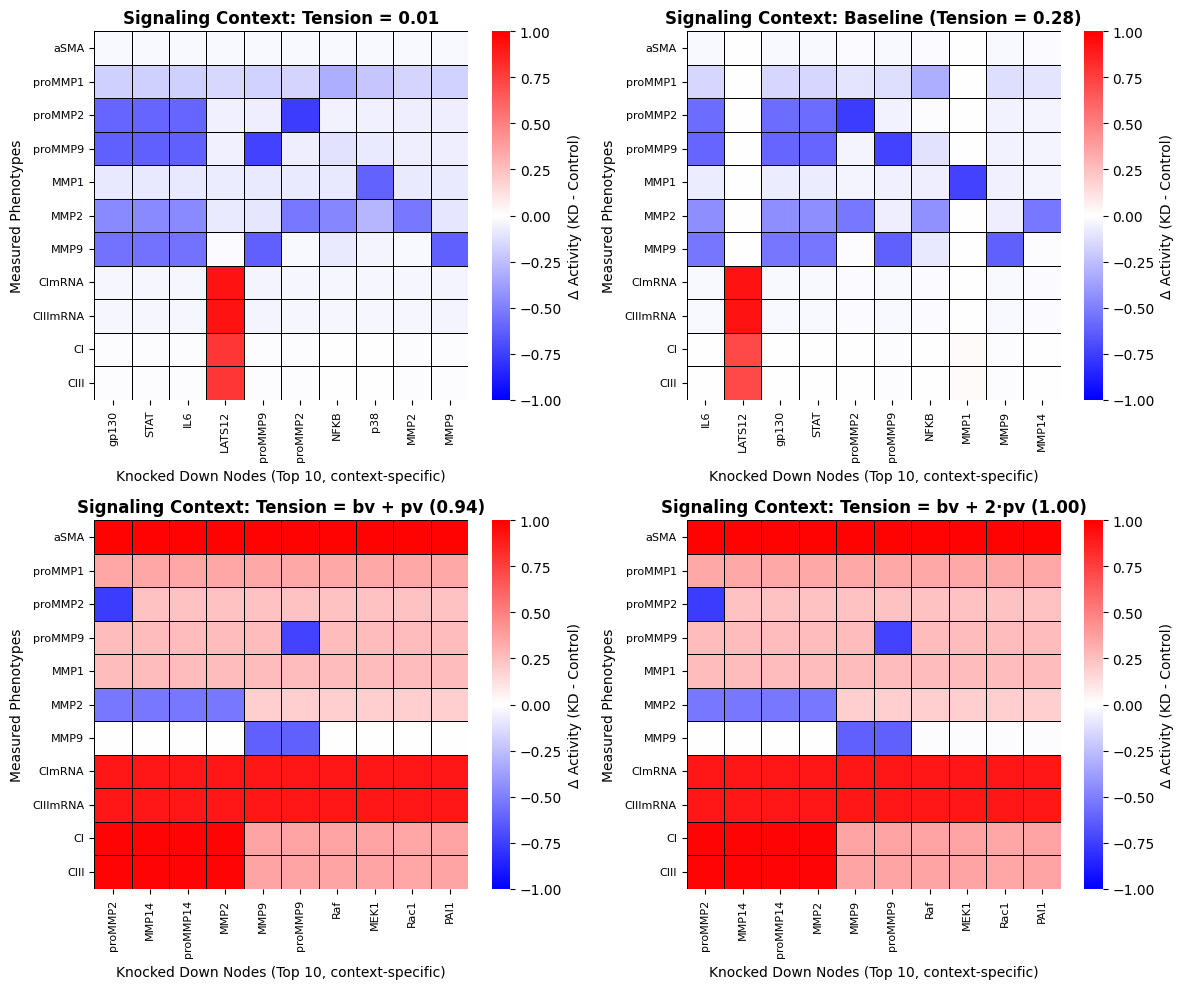

In [11]:
# ------- plot 2x2 figure (each panel uses its own top-10 KD list) -------
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
vmin, vmax = -1, 1  # keep a fixed, symmetric scale for comparability

for ax, (title, df_sub) in zip(axes.ravel(), context_panels):
    hm = sns.heatmap(df_sub, ax=ax, cmap="bwr", center=0, vmin=vmin, vmax=vmax,
                     linewidths=0.5, linecolor="black", cbar=True,
                     cbar_kws={"label": "Δ Activity (KD - Control)"})
    ax.set_title(f"Signaling Context: {title}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Knocked Down Nodes (Top 10, context-specific)", fontsize=10, labelpad=6)
    ax.set_ylabel("Measured Phenotypes", fontsize=10, labelpad=6)
    ax.tick_params(axis='x', labelrotation=90, labelsize=8)
    ax.tick_params(axis='y', labelsize=8)

fig.tight_layout()
plt.show()
fig.savefig("KD_heatmaps_four_tension_levels_baseline.png", dpi=300, bbox_inches="tight")

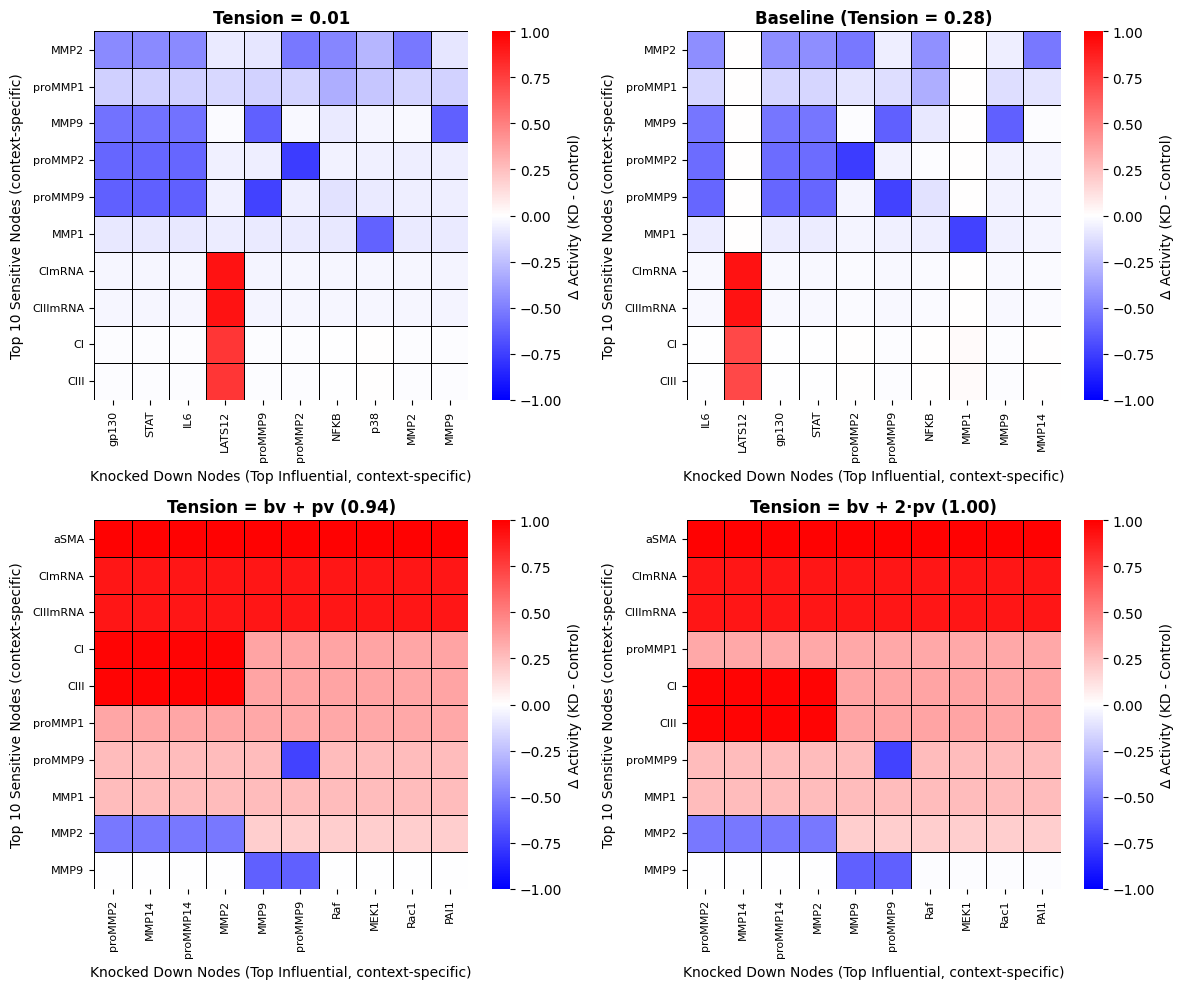

In [12]:
# =========================== Helpers ===========================
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from scipy.integrate import ode

def _simulate_ss(y0_vec):
    """Return steady-state y for given y0 under current params."""
    t0, tf = 0.0, 60.0
    dt = tf / 6000.0
    r = ode(NetfluxODE_5.ODEfunc).set_integrator('vode', method='adams',
             order=10, rtol=0, atol=1e-6, with_jacobian=False)
    r.set_initial_value(y0_vec, t0).set_f_params(tau, ymax, w_vec, n, EC50)
    while r.successful() and r.t <= tf:
        r.integrate(r.t + dt)
    return r.y.copy()

def _kd_matrix_for_context(y0_vec):
    """
    Matrix of KD deltas at steady state; rows=measured species, cols=KD nodes.
    (We compute full species x species and then can subset rows later.)
    """
    baseline_ss = _simulate_ss(y0_base)
    m = len(speciesNames)
    SA = np.empty((m, m), dtype=float)  # row: KD node, col: measured (we'll transpose)
    for i in range(m):
        S = np.eye(m)
        S[i, i] = 0.0  # knock down node i
        y0_kd = S @ y0_vec
        r = ode(NetfluxODE_5_sensitivity.ODEfunc).set_integrator(
            'vode', method='adams', order=10, rtol=0, atol=1e-6, with_jacobian=False
        )
        r.set_initial_value(y0_kd, 0.0).set_f_params(tau, ymax, w_vec, n, EC50, S)
        tf = 60.0; dt = tf / 6000.0
        while r.successful() and r.t <= tf:
            r.integrate(r.t + dt)
        SA[i, :] = r.y - baseline_ss
    return pd.DataFrame(SA.T, index=speciesNames, columns=speciesNames)  # rows=measured, cols=KD

def _pick_measured_nodes():
    default = ["aSMA","proMMP1","proMMP2","proMMP9","MMP1","MMP2","MMP9",
               "CImRNA","CIIImRNA","CI","CIII"]
    try:
        return [n for n in phenotypic_outputs if n in speciesNames]
    except NameError:
        return [n for n in default if n in speciesNames]

# ==================== Build the 2×2 sensitivity vs influence figure ====================
threshold_abs = 0.25  # "≥25%" on a 0–1 scale
topk_rows = 10        # top sensitive (rows)
topk_cols = 10        # top influential (columns)

contexts = [
    ("Tension = 0.01",                 0.01),
    (f"Baseline (Tension = {bv:.2f})", float(bv)),
    (f"Tension = bv + pv ({bv+pv:.2f})", float(bv + pv)),
    (f"Tension = bv + 2·pv (1.00)",    1.00),
]

measured_nodes = _pick_measured_nodes()
if len(measured_nodes) == 0:
    raise ValueError("No measured/phenotypic nodes found. Check phenotypic_outputs or speciesNames.")

vmin, vmax = -1, 1   # color scale consistent across panels

# For optional exports
sens_tables = {}        # per context sensitivity scores (Series indexed by measured node)
infl_tables = {}        # per context influence scores (Series indexed by KD node)
top_sensitive_lists = {}
top_influential_lists = {}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (title, tens) in zip(axes.ravel(), contexts):
    # 1) KD matrix for this tension (rows=all measured species, cols=all KD nodes)
    y0_ctx = y0.copy()
    y0_ctx[mechanical] = float(tens)
    df_full = _kd_matrix_for_context(y0_ctx)

    # Restrict to phenotypes on the rows for scoring
    M = df_full.loc[measured_nodes]  # rows = measured (phenotypes), cols = KD nodes

    # 2) Sensitivity per measured node = count of KD columns with |Δ| >= threshold
    sens_counts = (M.abs() >= threshold_abs).sum(axis=1).sort_values(ascending=False)
    top_sensitive = sens_counts.head(topk_rows).index.tolist()

    # 3) Influence per KD node = count of measured rows with |Δ| >= threshold
    infl_counts = (M.abs() >= threshold_abs).sum(axis=0).sort_values(ascending=False)
    top_influential = infl_counts.head(topk_cols).index.tolist()

    # Save tables/lists
    sens_tables[title] = sens_counts.copy()
    infl_tables[title] = infl_counts.copy()
    top_sensitive_lists[title] = top_sensitive
    top_influential_lists[title] = top_influential

    # 4) Subset for plotting: rows=top sensitive (context-specific), cols=top influential (context-specific)
    df_sub = M.loc[top_sensitive, top_influential]

    # 5) Plot heatmap
    hm = sns.heatmap(df_sub, ax=ax, cmap="bwr", center=0, vmin=vmin, vmax=vmax,
                     linewidths=0.5, linecolor="black", cbar=True,
                     cbar_kws={"label": "Δ Activity (KD - Control)"})
    ax.set_title(f"{title}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Knocked Down Nodes (Top Influential, context-specific)", fontsize=10, labelpad=6)
    ax.set_ylabel("Top 10 Sensitive Nodes (context-specific)", fontsize=10, labelpad=6)
    ax.tick_params(axis='x', labelrotation=90, labelsize=8)
    ax.tick_params(axis='y', labelsize=8)

fig.tight_layout()
plt.show()

# ============ Optional: export per-context rankings ============
# Sensitivity tables (rows = measured node, columns = context)
sens_df = pd.concat({ctx: tbl for ctx, tbl in sens_tables.items()}, axis=1)
sens_df.columns = [ctx for ctx, _ in contexts]
sens_df.to_csv("sensitivity_counts_by_context.csv")

# Influence tables (rows = KD node, columns = context)
infl_df = pd.concat({ctx: tbl for ctx, tbl in infl_tables.items()}, axis=1)
infl_df.columns = [ctx for ctx, _ in contexts]
infl_df.to_csv("influence_counts_by_context.csv")

# Optional: write the actual top-10 lists per context
pd.Series({k: ", ".join(v) for k, v in top_sensitive_lists.items()}).to_csv("top_sensitive_lists.csv", header=False)
pd.Series({k: ", ".join(v) for k, v in top_influential_lists.items()}).to_csv("top_influential_lists.csv", header=False)



### case 2 where columns do not change per tension level so all relevant nodes for all tension levels are always shown

Total influential nodes across all contexts: 17


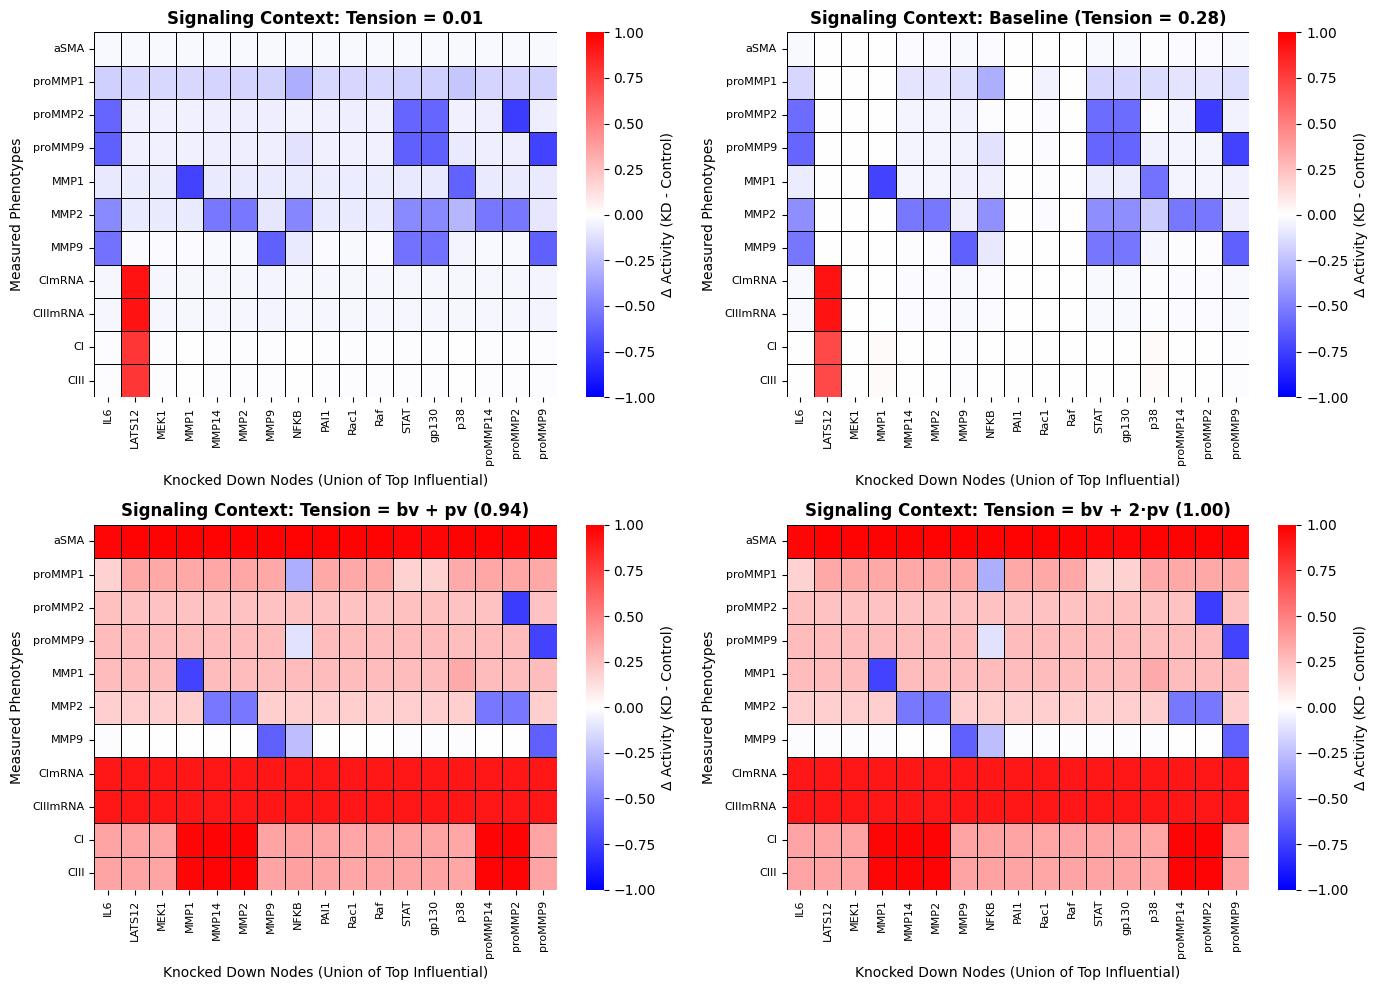

In [13]:
# ==================== Build comparable figure across contexts ====================
threshold = 0.25   # your influence threshold on phenotypes
K = 10             # top-K per context (before union)
MODE = "count"

context_panels = {}
top_nodes_by_context = {}

for title, tens in tension_levels:
    # Build context y0
    y0_ctx = y0_base.copy()
    y0_ctx[mechanical] = float(tens)

    # Full KD matrix for this context
    df_full_ctx = _kd_matrix_for_context(y0_ctx)
    df_full_ctx = df_full_ctx.loc[measured_nodes]  # restrict rows to phenotypes

    # Compute top-K influential nodes for this context
    if MODE == "count":
        infl_scores = (df_full_ctx.abs() >= threshold).sum(axis=0)
    elif MODE == "mean":
        infl_scores = df_full_ctx.abs().mean(axis=0)
    top_nodes_ctx = infl_scores.sort_values(ascending=False).head(K).index.tolist()

    top_nodes_by_context[title] = top_nodes_ctx
    context_panels[title] = df_full_ctx

# Step 1: union of all top influential nodes across contexts
all_influential_nodes = sorted(set().union(*top_nodes_by_context.values()))
print(f"Total influential nodes across all contexts: {len(all_influential_nodes)}")

# Step 2: re-subset each context to the same union of columns
context_subsets_aligned = []
for title, tens in tension_levels:
    df_full_ctx = context_panels[title]
    # Align columns: take only union, fill missing if any
    df_subset = df_full_ctx.reindex(columns=all_influential_nodes)
    context_subsets_aligned.append((title, df_subset))

# Step 3: plot with shared columns
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
vmin, vmax = -1, 1

for ax, (title, df_sub) in zip(axes.ravel(), context_subsets_aligned):
    hm = sns.heatmap(df_sub, ax=ax, cmap="bwr", center=0, vmin=vmin, vmax=vmax,
                     linewidths=0.5, linecolor="black", cbar=True,
                     cbar_kws={"label": "Δ Activity (KD - Control)"})
    ax.set_title(f"Signaling Context: {title}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Knocked Down Nodes (Union of Top Influential)", fontsize=10, labelpad=6)
    ax.set_ylabel("Measured Phenotypes", fontsize=10, labelpad=6)
    ax.tick_params(axis='x', labelrotation=90, labelsize=8)
    ax.tick_params(axis='y', labelsize=8)

fig.tight_layout()
plt.show()
fig.savefig("KD_heatmaps_four_tensions_union_baseline.png", dpi=300, bbox_inches="tight")


### Following plot is to visualize the 10 top senstivie nodes vs 10 top influential nodes at each tension level

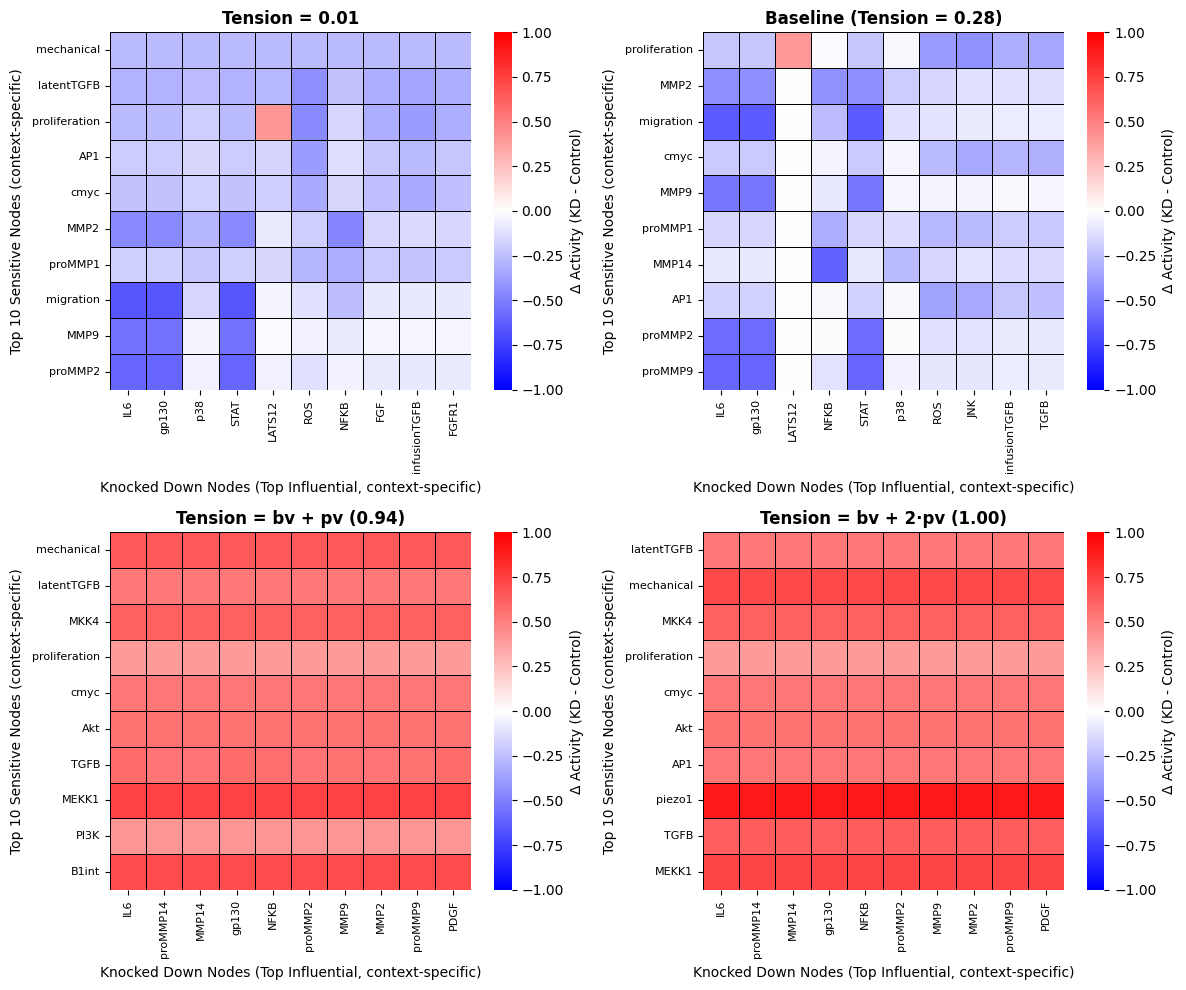

In [14]:
# ==================== Build the 2×2 sensitivity vs influence figure ====================
threshold_abs = 0.25  # ≥25% change
topk_rows = 10        # top sensitive (rows)
topk_cols = 10        # top influential (columns)

contexts = [
    ("Tension = 0.01",                 0.01),
    (f"Baseline (Tension = {bv:.2f})", float(bv)),
    (f"Tension = bv + pv ({bv+pv:.2f})", float(bv + pv)),
    (f"Tension = bv + 2·pv (1.00)",    1.00),
]

vmin, vmax = -1, 1   # fixed color scale

sens_tables = {}
infl_tables = {}
top_sensitive_lists = {}
top_influential_lists = {}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (title, tens) in zip(axes.ravel(), contexts):
    # 1) KD matrix for this context (rows=all species, cols=all KD nodes)
    y0_ctx = y0.copy()
    y0_ctx[mechanical] = float(tens)
    df_full = _kd_matrix_for_context(y0_ctx)  # rows=all measured species, cols=all KD

    # 2) Sensitivity per measured node = count of KD columns with |Δ| >= threshold
    sens_counts = (df_full.abs() >= threshold_abs).sum(axis=1).sort_values(ascending=False)
    top_sensitive = sens_counts.head(topk_rows).index.tolist()

    # 3) Influence per KD node = count of measured rows with |Δ| >= threshold
    infl_counts = (df_full.abs() >= threshold_abs).sum(axis=0).sort_values(ascending=False)
    top_influential = infl_counts.head(topk_cols).index.tolist()

    # Save tables/lists
    sens_tables[title] = sens_counts.copy()
    infl_tables[title] = infl_counts.copy()
    top_sensitive_lists[title] = top_sensitive
    top_influential_lists[title] = top_influential

    # 4) Subset for plotting: rows=top sensitive, cols=top influential
    df_sub = df_full.loc[top_sensitive, top_influential]

    # 5) Plot heatmap
    hm = sns.heatmap(df_sub, ax=ax, cmap="bwr", center=0, vmin=vmin, vmax=vmax,
                     linewidths=0.5, linecolor="black", cbar=True,
                     cbar_kws={"label": "Δ Activity (KD - Control)"})
    ax.set_title(f"{title}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Knocked Down Nodes (Top Influential, context-specific)", fontsize=10, labelpad=6)
    ax.set_ylabel("Top 10 Sensitive Nodes (context-specific)", fontsize=10, labelpad=6)
    ax.tick_params(axis='x', labelrotation=90, labelsize=8)
    ax.tick_params(axis='y', labelsize=8)

fig.tight_layout()
plt.show()

# ============ Optional: export per-context rankings ============



### Top 10 influential on each phenotypic output: case 1

In [ ]:
# ================= Per-phenotype top-10 influential (context-specific) =================
# Uses df_full_ctx (rows = species, cols = KD nodes) from _kd_matrix_for_context(y0_ctx)
# NOTE: self-KO columns are excluded for each phenotype (e.g., MMP1 KO is not allowed
# to appear in MMP1's top-10 influencers).

measured_nodes = _pick_measured_nodes()
if len(measured_nodes) == 0:
    raise ValueError("No measured/phenotypic nodes found. Check phenotypic_outputs or speciesNames.")

y0_base = y0.copy()
try:
    mechanical
except NameError:
    raise NameError("Please define the index 'mechanical' for the mechanical/tension input.")

tension_levels = [
    ("Tension = 0.01",                    0.01),
    (f"Baseline (Tension = {bv:.2f})",     float(bv)),
    (f"Tension = bv + pv ({bv+pv:.2f})",   float(bv + pv)),
    (f"Tension = bv + 2·pv (1.00)",        1.00),
]

TOPK = 10
vmin, vmax = -1, 1  # fixed scale for comparability

context_to_perphen_df = {}     # {title: {phenotype: df_1xK}}
context_to_perphen_cols = {}   # {title: {phenotype: [KD1,...,KDk]}}

for title, tens in tension_levels:
    y0_ctx = y0_base.copy()
    y0_ctx[mechanical] = float(tens)

    df_full_ctx = _kd_matrix_for_context(y0_ctx)

    perphen = {}
    percols = {}
    for phen in measured_nodes:
        if phen not in df_full_ctx.index:
            continue
        # Rank KDs by absolute effect on THIS phenotype, EXCLUDING self-KO
        effects = (df_full_ctx.loc[phen]
                              .drop(labels=[phen], errors='ignore')
                              .abs()
                              .sort_values(ascending=False))
        top_cols = effects.index[:TOPK].tolist()
        percols[phen] = top_cols
        perphen[phen] = df_full_ctx.loc[[phen], top_cols]

    context_to_perphen_df[title] = perphen
    context_to_perphen_cols[title] = percols


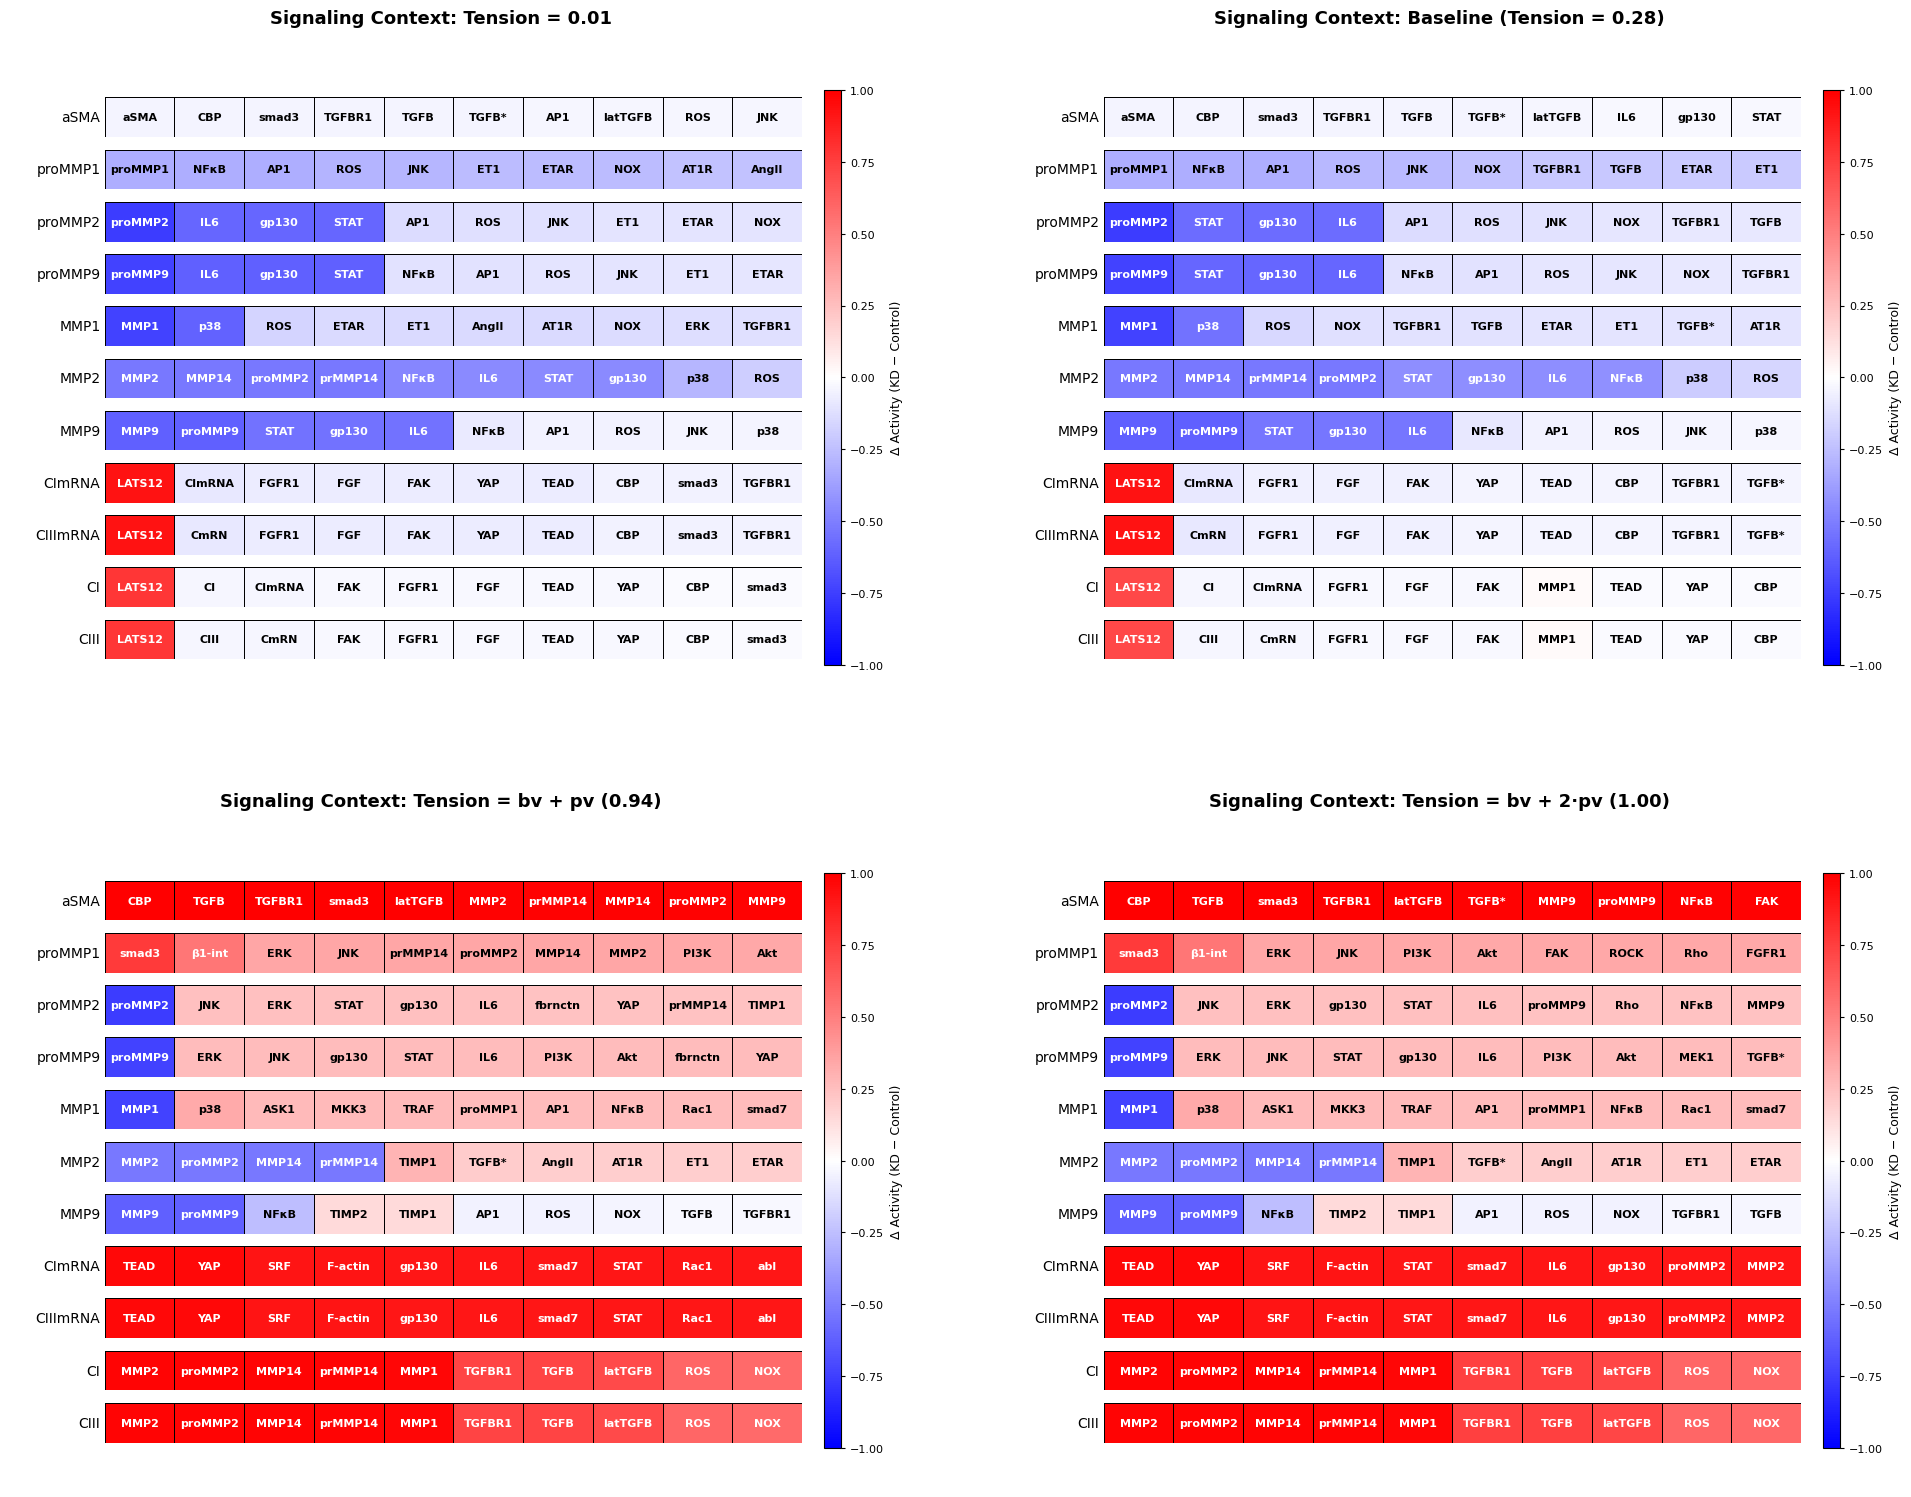

In [16]:
# ========================= Plot: 2×2 contexts, per-phenotype top-10 with in-cell labels =========================
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# --- tunables ---
MAX_LABEL_CHARS = 7     # shorten KD labels to this many characters inside cells
CELL_FONTSIZE   = 8
PHEN_FONTSIZE   = 10
CB_FONTSIZE     = 9
STRIP_PAD_TOP   = 0.14   # fraction of strip height reserved for top padding
STRIP_PAD_BOT   = 0.10   # bottom padding

# Optional manual aliases for long names (add/extend as you see fit)
ALIAS = {
    "infusionTGFB": "TGFB*",
    "latentTGFB": "latTGFB",
    "mechanical": "mech",
    "TEAD": "TEAD",
    "Factin": "F-actin",
    "B1int": "β1-int",
    "TGFB1R": "TGFBR1",
    "NFKB": "NFκB",
}

def shorten(label, max_chars=MAX_LABEL_CHARS):
    """Manual alias > consonant-heavy shrink > crop."""
    s = str(label)
    if s in ALIAS:
        return ALIAS[s]
    # keep letters/digits; drop vowels after first char
    core = ''.join(ch for ch in s if ch.isalnum())
    if len(core) <= max_chars:
        return core
    # remove vowels except first character to compact
    head = core[0]
    tail = ''.join(ch for ch in core[1:] if ch.lower() not in "aeiou")
    out = (head + tail)[:max_chars]
    return out

def text_color_for_value(val, vmin=-0.25, vmax=0.25, mid=0.0):
    """Choose black/white text for contrast on diverging background."""
    # normalize |val| within range; stronger = use white
    span = max(abs(vmin - mid), abs(vmax - mid))
    intensity = abs(val - mid) / span if span > 0 else 0.0
    return "white" if intensity >= 0.35 else "black"

nrows_per_context = len(measured_nodes)

# infer K (should be 10)
_any_title = next(iter(context_to_perphen_df))
_any_phen  = next(iter(context_to_perphen_df[_any_title]))
K = context_to_perphen_df[_any_title][_any_phen].shape[1]

# make it roomy
fig_w = max(18, 1.4*K + 10)
fig_h = max(12, 1.15*nrows_per_context + 6)

fig, axes = plt.subplots(2, 2, figsize=(fig_w, fig_h))
plt.subplots_adjust(wspace=0.16, hspace=0.20)

for ax_panel, (title, tens) in zip(axes.ravel(), tension_levels):
    ax_panel.set_axis_off()
    perphen = context_to_perphen_df[title]

    # layout within panel
    top_margin, bottom_margin = 0.06, 0.06
    usable_h = 1.0 - top_margin - bottom_margin
    strip_h  = usable_h / max(1, nrows_per_context)

    cax = ax_panel.inset_axes([0.945, bottom_margin, 0.02, usable_h])
    sm = plt.cm.ScalarMappable(norm=plt.Normalize(vmin=vmin, vmax=vmax), cmap="bwr")
    cb = fig.colorbar(sm, cax=cax)
    cb.ax.tick_params(labelsize=CB_FONTSIZE-1, length=3)
    cb.set_label("Δ Activity (KD − Control)", fontsize=CB_FONTSIZE)

    ax_panel.set_title(f"Signaling Context: {title}", fontsize=13, fontweight="bold", y=1.03)

    for idx, phen in enumerate(measured_nodes):
        if phen not in perphen:
            continue
        df_row = perphen[phen]   # 1×K
        vals   = df_row.values[0]  # numpy 1D

        # inset for heatmap strip
        y0 = 1.0 - top_margin - (idx + 1) * strip_h
        ax_in = ax_panel.inset_axes([0.11, y0 + STRIP_PAD_BOT*strip_h,
                                     0.81, (1.0-STRIP_PAD_TOP-STRIP_PAD_BOT)*strip_h])

        # draw heatmap without x/y tick labels
        sns.heatmap(df_row, ax=ax_in, cmap="bwr", center=0, vmin=vmin, vmax=vmax,
                    cbar=False, linewidths=0.5, linecolor="black",
                    xticklabels=False, yticklabels=False)

        # add KD names INSIDE cells
        for j, kd in enumerate(df_row.columns):
            lab = shorten(kd)
            val = float(vals[j])
            ax_in.text(j + 0.5, 0.5, lab,
                       ha="center", va="center",
                       fontsize=CELL_FONTSIZE, fontweight="bold",
                       color=text_color_for_value(val, vmin=vmin, vmax=vmax))

            # optional: also show small rank below the label

        # phenotype label in left gutter
        ax_lab = ax_panel.inset_axes([0.02, y0 + STRIP_PAD_BOT*strip_h,
                                      0.085, (1.0-STRIP_PAD_TOP-STRIP_PAD_BOT)*strip_h])
        ax_lab.set_axis_off()
        ax_lab.text(1.0, 0.5, phen, ha="right", va="center", fontsize=PHEN_FONTSIZE)

        # clean edges
        for spine in ax_in.spines.values():
            spine.set_linewidth(0.6)

plt.show()
fig.savefig("per_phenotype_top10_KD_incell_labels_baseline.png", dpi=300, bbox_inches="tight")



In [ ]:
# ==================== Union-of-all KD columns across phenotypes & tensions ====================
# Self-cells (row species == column KO target) are left white and marked with an X.

from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1) Union of KD columns across all (context, phenotype) top-10 lists
all_kds = []
for title, perphen_cols in context_to_perphen_cols.items():
    for kd_list in perphen_cols.values():
        all_kds.extend(kd_list)
union_kd_nodes = sorted(set(all_kds))

if len(union_kd_nodes) == 0:
    raise ValueError("No KD columns found in per-phenotype selections; nothing to union.")

# 2) Per-context matrices restricted to measured nodes
context_M = {}
for title, tens in tension_levels:
    y0_ctx = y0_base.copy()
    y0_ctx[mechanical] = float(tens)
    df_full_ctx = _kd_matrix_for_context(y0_ctx)
    context_M[title] = df_full_ctx.loc[measured_nodes]

counts = Counter(all_kds)

global_mean_abs = {}
for kd in union_kd_nodes:
    vals = []
    for title in tension_levels:
        M = context_M[title[0]]
        if kd in M.columns:
            vals.append(M[kd].abs().values)
    global_mean_abs[kd] = float(np.mean(np.concatenate(vals))) if vals else 0.0

union_kd_nodes_sorted = sorted(
    union_kd_nodes,
    key=lambda k: (counts.get(k, 0), global_mean_abs.get(k, 0.0)),
    reverse=True
)

print(f"Union KD columns: {len(union_kd_nodes_sorted)}")

# 3) Aligned matrices for plotting
panels_aligned = []
for title, _ in tension_levels:
    M = context_M[title]
    df_sub = M.reindex(columns=union_kd_nodes_sorted)
    panels_aligned.append((title, df_sub))

# 4) Plot
def _wrap_labels(labels, max_chunk=10):
    out = []
    for s in labels:
        s = str(s)
        out.append(s if len(s) <= max_chunk
                   else "\n".join(s[i:i+max_chunk] for i in range(0, len(s), max_chunk)))
    return out

ncols = len(union_kd_nodes_sorted)
fig_w = max(14, 0.45 * ncols + 8)
fig_h = 10
vmin, vmax = -1, 1

fig, axes = plt.subplots(4, 1, figsize=(fig_w*2/3, fig_h*2))
for ax, (title, df_sub) in zip(axes.ravel(), panels_aligned):
    # Mask self-cells (row label == column label) so they render white
    self_mask = pd.DataFrame(
        [[r == c for c in df_sub.columns] for r in df_sub.index],
        index=df_sub.index, columns=df_sub.columns
    )

    sns.heatmap(
        df_sub,
        ax=ax,
        cmap="bwr",
        center=0,
        vmin=vmin, vmax=vmax,
        linewidths=0.5, linecolor="black",
        cbar=True,
        cbar_kws={"label": "Δ Activity (KD − Control)"},
        mask=self_mask,
        xticklabels=_wrap_labels(df_sub.columns, max_chunk=10),
    )

    # Overlay X on the masked (self) cells
    for i, row_lbl in enumerate(df_sub.index):
        for j, col_lbl in enumerate(df_sub.columns):
            if row_lbl == col_lbl:
                ax.plot(j + 0.5, i + 0.5, marker='x', color='black',
                        markersize=10, markeredgewidth=2)

    ax.set_title(f"Signaling Context: {title}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Knocked Down Nodes (Union across all tensions & phenotypes)",
                  fontsize=10, labelpad=6)
    ax.set_ylabel("Measured Phenotypes", fontsize=10, labelpad=6)
    ax.tick_params(axis='x', labelrotation=90, labelsize=8)
    ax.tick_params(axis='y', labelsize=9)

fig.tight_layout()
plt.show()
fig.savefig("KD_heatmaps_union_all_tensions_all_phenotypes_baseline.png", dpi=300, bbox_inches="tight")
